# ECE 285 HW2: DCGAN on WikiArt

**Kaggle setup (do this before you click Run All):**
1. **Settings → Accelerator → GPU T4 x2** (one GPU is used). Pick T4 rather than P100, because recent PyTorch builds no longer support the P100.
2. **Settings → Internet → On.** It's needed for `pip install pytorch-ignite` and the Inception-v3 weights used by FID/IS.
3. **Add Input → search "wikiart" → add `steubk/wikiart`.** The notebook finds the images anywhere under `/kaggle/input`.
4. Use **Save Version → Save & Run All (Commit)** so it keeps running in the background. All figures, `results.json` and checkpoints end up in `/kaggle/working/outputs`, and `hw2_outputs.zip` holds them all.

Expected runtime on a T4 is about 25–35 min: roughly 3 min of preprocessing, 15–20 min of training for 80 epochs, and a few minutes of FID/IS. `TIME_BUDGET_MIN` stops training early if things run slow.

Pipeline: 20k random WikiArt paintings → center-crop and resize to 64×64 (cached as uint8 on the GPU) → DCGAN (Radford et al., 2016) → FID and IS via `ignite.metrics` as in the pytorch-ignite GAN evaluation blog.

In [1]:
# Install pytorch-ignite if it isn't already there (needs Internet ON)
import importlib.util, subprocess, sys
if importlib.util.find_spec("ignite") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytorch-ignite"], check=True)

In [2]:
import os, time, json, math, copy, random, shutil
import multiprocessing as mp
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.utils as vutils
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm
import ignite
from ignite.metrics import FID, InceptionScore

Image.MAX_IMAGE_PIXELS = None          # some WikiArt scans are huge
ImageFile.LOAD_TRUNCATED_IMAGES = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| ignite", ignite.__version__)
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
if device.type == "cuda":
    torch.zeros(1, device=device) + 1   # fails fast here if the GPU arch is unsupported (e.g. P100)
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: no GPU. Turn on the GPU accelerator in Settings.")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | ignite 0.5.5
device: cuda Tesla T4


In [3]:
# ---------------- Config ----------------
SEED          = 42
DATA_ROOT     = "/kaggle/input"            # searched recursively for images
OUT_DIR       = "/kaggle/working/outputs"
CACHE_DIR     = "/kaggle/temp" if os.path.isdir("/kaggle/temp") else "/tmp"

N_IMAGES      = 20000      # subset of WikiArt (Piazza #80/#102: 10k-20k is fine)
STYLES        = None       # None = all 27 styles; or e.g. ["Impressionism", "Post_Impressionism"]
IMG_SIZE      = 64         # the DCGAN below is built for 64x64
HFLIP         = True       # random horizontal flip augmentation

NZ, NGF, NDF  = 100, 64, 64
BATCH_SIZE    = 128
EPOCHS        = 80
LR_G, LR_D    = 2e-4, 2e-4
BETAS         = (0.5, 0.999)
REAL_LABEL    = 0.9        # one-sided label smoothing (1.0 = off)
TIME_BUDGET_MIN = 70       # stop training after this many minutes

EVAL_EVERY    = 5          # epochs between FID/IS tracking evals
N_EVAL_TRACK  = 2500       # samples per tracking eval (> 2048 so the feature covariance is full rank)
N_EVAL_FINAL  = 10000      # samples for the final reported numbers
EVAL_BS       = 100

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
CONFIG = {k: v for k, v in dict(globals()).items()
          if k.isupper() and len(k) > 1 and isinstance(v, (int, float, str, bool, tuple, list, type(None)))}
CONFIG

{'SEED': 42,
 'DATA_ROOT': '/kaggle/input',
 'OUT_DIR': '/kaggle/working/outputs',
 'CACHE_DIR': '/tmp',
 'N_IMAGES': 20000,
 'STYLES': None,
 'IMG_SIZE': 64,
 'HFLIP': True,
 'NZ': 100,
 'NGF': 64,
 'NDF': 64,
 'BATCH_SIZE': 128,
 'EPOCHS': 80,
 'LR_G': 0.0002,
 'LR_D': 0.0002,
 'BETAS': (0.5, 0.999),
 'REAL_LABEL': 0.9,
 'TIME_BUDGET_MIN': 70,
 'EVAL_EVERY': 5,
 'N_EVAL_TRACK': 2500,
 'N_EVAL_FINAL': 10000,
 'EVAL_BS': 100}

## 1. Data: sample a subset and cache it at 64×64

In [4]:
EXTS = (".jpg", ".jpeg", ".png")
all_paths = []
for root, _, files in os.walk(DATA_ROOT):
    for f in files:
        if f.lower().endswith(EXTS):
            all_paths.append(os.path.join(root, f))
all_paths.sort()
style_of = lambda p: os.path.basename(os.path.dirname(p))
if STYLES is not None:
    all_paths = [p for p in all_paths if style_of(p) in set(STYLES)]
assert len(all_paths) > 0, f"No images found under {DATA_ROOT}. Did you add the steubk/wikiart dataset?"

styles = sorted(set(map(style_of, all_paths)))
print(f"{len(all_paths)} images in {len(styles)} styles")

rng = np.random.default_rng(SEED)
n_take = min(len(all_paths), int(N_IMAGES * 1.02) + 16)   # small surplus for unreadable files
sel_paths = [all_paths[i] for i in rng.choice(len(all_paths), n_take, replace=False)]

81444 images in 27 styles


In [5]:
def load_one(path, size=IMG_SIZE):
    # Shorter side -> size, then center crop. JPEG draft mode decodes at reduced scale (much faster).
    try:
        with Image.open(path) as im:
            im.draft("RGB", (size * 2, size * 2))
            im = im.convert("RGB")
            w, h = im.size
            s = size / min(w, h)
            nw, nh = max(size, round(w * s)), max(size, round(h * s))
            im = im.resize((nw, nh), Image.LANCZOS)
            l, t = (nw - size) // 2, (nh - size) // 2
            return np.asarray(im.crop((l, t, l + size, t + size)), dtype=np.uint8)
    except Exception:
        return None

cache_file = os.path.join(CACHE_DIR, f"wikiart_{IMG_SIZE}_{N_IMAGES}_{SEED}_{'all' if STYLES is None else '-'.join(STYLES)}.npy")
if os.path.exists(cache_file):
    data_np = np.load(cache_file)
    print("loaded cache", cache_file)
else:
    t0 = time.time()
    with mp.get_context("fork").Pool(os.cpu_count()) as pool:
        imgs = list(tqdm(pool.imap(load_one, sel_paths, chunksize=32), total=len(sel_paths), desc="preprocess"))
    n_bad = sum(x is None for x in imgs)
    imgs = [x for x in imgs if x is not None][:N_IMAGES]
    data_np = np.stack(imgs).transpose(0, 3, 1, 2).copy()          # N,3,H,W uint8
    np.save(cache_file, data_np)
    print(f"preprocessed {len(imgs)} images ({n_bad} unreadable) in {time.time()-t0:.0f}s")
N = data_np.shape[0]
print("dataset tensor:", data_np.shape, f"{data_np.nbytes/1e6:.0f} MB")

data = torch.from_numpy(data_np).to(device)     # whole dataset lives on the GPU as uint8
u8_to_float = lambda x: x.float().div(127.5).sub(1.0)   # -> [-1, 1]

preprocess:   0%|          | 0/20416 [00:00<?, ?it/s]

preprocessed 20000 images (0 unreadable) in 298s
dataset tensor: (20000, 3, 64, 64) 246 MB


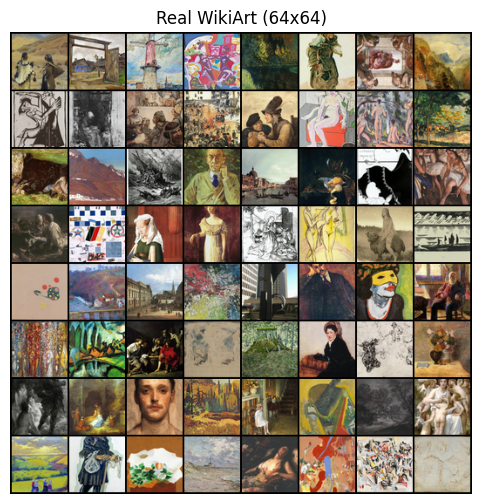

In [6]:
def save_grid(x, name, nrow=8, title=None, figsize=(6, 6)):
    # x in [-1,1], saves PNG + PDF (PDF for the LaTeX report)
    grid = vutils.make_grid(x.detach().float().cpu(), nrow=nrow, padding=2, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=figsize); plt.axis("off")
    if title: plt.title(title)
    plt.imshow(grid.permute(1, 2, 0).numpy())
    for ext in ("png", "pdf"):
        plt.savefig(os.path.join(OUT_DIR, f"{name}.{ext}"), bbox_inches="tight", dpi=200)
    plt.show()

save_grid(u8_to_float(data[torch.randperm(N, device=device)[:64]]), "real_samples", title="Real WikiArt (64x64)")

## 2. DCGAN model

In [7]:
class Generator(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF):
        super().__init__()
        def up(i, o): return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 8), nn.ReLU(True),  # 4x4
            *up(ngf * 8, ngf * 4),   # 8x8
            *up(ngf * 4, ngf * 2),   # 16x16
            *up(ngf * 2, ngf),       # 32x32
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh())  # 64x64
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, ndf=NDF):
        super().__init__()
        def down(i, o): return [nn.Conv2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),   # 32x32
            *down(ndf, ndf * 2),       # 16x16
            *down(ndf * 2, ndf * 4),   # 8x8
            *down(ndf * 4, ndf * 8),   # 4x4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False))                      # logit
    def forward(self, x): return self.net(x).view(-1)

def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

G, D = Generator().to(device), Discriminator().to(device)
G.apply(weights_init); D.apply(weights_init)
optG = torch.optim.Adam(G.parameters(), lr=LR_G, betas=BETAS)
optD = torch.optim.Adam(D.parameters(), lr=LR_D, betas=BETAS)
criterion = nn.BCEWithLogitsLoss()      # = sigmoid + BCE, numerically stable
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"G params: {n_params(G)/1e6:.2f}M | D params: {n_params(D)/1e6:.2f}M")

G params: 3.58M | D params: 2.77M


## 3. FID and Inception Score (pytorch-ignite)
These use `ignite.metrics.FID` and `InceptionScore` as in the pytorch-ignite blog: images are resized to 299×299 with bilinear interpolation. Three corrections:
* **FID features.** When no feature extractor is passed, ignite's `FID()` computes the distance on Inception's **1000-class softmax probabilities**, which gives tiny values (around 0.05). Here it uses the standard **2048-d pool3 features** (`InceptionModel(return_features=True)`, `num_features=2048`), so the values are on the usual FID scale.
* **Input normalization.** torchvision's pretrained Inception has `transform_input=True`, so it expects ImageNet-normalized input. Images are mapped [-1,1] → [0,1] → ImageNet mean/std (the blog passes raw [0,1]).
* Resizing runs batched on the GPU (`F.interpolate`) instead of per-image PIL.

FID compares generated images with real training images. A real-vs-real FID (two disjoint halves of the data) is reported as a floor. The weights are torchvision's, not the TF FID weights, so values are close to, but not exactly comparable with, published FIDs.

In [8]:
from ignite.metrics.gan.utils import InceptionModel
fid_metric = FID(num_features=2048, feature_extractor=InceptionModel(return_features=True, device=device), device=device)
is_metric = InceptionScore(device=device)
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMNET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_inception(x):
    x = (x.clamp(-1, 1) + 1) / 2
    x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
    return (x - IMNET_MEAN) / IMNET_STD

@torch.no_grad()
def evaluate(gen, n, bs=EVAL_BS):
    n = min(n, N)
    was_training = gen.training; gen.eval()
    fid_metric.reset(); is_metric.reset()
    perm = torch.randperm(N, device=device)[:n]
    for i in range(0, n, bs):
        b = min(bs, n - i)
        fake = to_inception(gen(torch.randn(b, NZ, 1, 1, device=device)))
        real = to_inception(u8_to_float(data[perm[i:i + b]]))
        fid_metric.update((fake, real))
        is_metric.update(fake)
    gen.train(was_training)
    return safe_fid(), float(is_metric.compute())

def safe_fid():
    try:
        return float(fid_metric.compute())
    except Exception as e:      # never let a metric failure kill training
        print("FID computation failed:", e); return float("nan")

@torch.no_grad()
def fid_real_vs_real(n, bs=EVAL_BS):
    # FID between two disjoint random halves of the real data = noise floor for this sample size
    n = min(n, N // 2); fid_metric.reset()
    perm = torch.randperm(N, device=device)
    a, b = perm[:n], perm[n:2 * n]
    for i in range(0, n, bs):
        fid_metric.update((to_inception(u8_to_float(data[a[i:i + bs]])), to_inception(u8_to_float(data[b[i:i + bs]]))))
    return safe_fid()

@torch.no_grad()
def inception_score_real(n, bs=EVAL_BS):
    n = min(n, N); is_metric.reset()
    perm = torch.randperm(N, device=device)[:n]
    for i in range(0, n, bs):
        is_metric.update(to_inception(u8_to_float(data[perm[i:i + bs]])))
    return float(is_metric.compute())

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 256MB/s] 


## 4. Training

In [9]:
def augment(x):
    if not HFLIP: return x
    flip = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    return torch.where(flip, x.flip(3), x)

fixed_noise = torch.randn(64, NZ, 1, 1, device=device, generator=torch.Generator(device).manual_seed(SEED))
iter_log = []                      # per-iteration [loss_D, loss_G, D(x), D(G(z))]
epoch_log, eval_log, snapshots = [], [], {}
best = {"fid": float("inf"), "epoch": None, "state": None}
iters_per_epoch = N // BATCH_SIZE
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    perm = torch.randperm(N, device=device)
    ep_stats = []
    for it in range(iters_per_epoch):
        real = augment(u8_to_float(data[perm[it * BATCH_SIZE:(it + 1) * BATCH_SIZE]]))
        b = real.size(0)

        # (1) D step: maximize log D(x) + log(1 - D(G(z)))
        fake = G(torch.randn(b, NZ, 1, 1, device=device))
        out_real, out_fake = D(real), D(fake.detach())
        loss_D = criterion(out_real, torch.full_like(out_real, REAL_LABEL)) + \
                 criterion(out_fake, torch.zeros_like(out_fake))
        optD.zero_grad(set_to_none=True); loss_D.backward(); optD.step()

        # (2) G step: non-saturating loss, maximize log D(G(z))
        out_g = D(fake)
        loss_G = criterion(out_g, torch.ones_like(out_g))
        optG.zero_grad(set_to_none=True); loss_G.backward(); optG.step()

        ep_stats.append(torch.stack([loss_D.detach(), loss_G.detach(),
                                     torch.sigmoid(out_real).mean().detach(),
                                     torch.sigmoid(out_fake).mean().detach()]))
    ep_stats = torch.stack(ep_stats).cpu().numpy()          # one GPU sync per epoch
    iter_log.append(ep_stats)
    m = ep_stats.mean(0)
    elapsed = time.time() - t_start
    epoch_log.append(dict(epoch=epoch, loss_D=float(m[0]), loss_G=float(m[1]), D_x=float(m[2]), D_Gz=float(m[3]), time_s=elapsed))

    with torch.no_grad():
        G.eval(); snapshots[epoch] = G(fixed_noise[:8]).cpu(); G.train()

    out_of_time = elapsed > TIME_BUDGET_MIN * 60
    msg = f"[{epoch:3d}/{EPOCHS}] loss_D {m[0]:.3f}  loss_G {m[1]:.3f}  D(x) {m[2]:.3f}  D(G(z)) {m[3]:.3f}  {elapsed/60:.1f} min"
    if epoch % EVAL_EVERY == 0 or epoch == EPOCHS or out_of_time:
        fid, isc = evaluate(G, N_EVAL_TRACK)
        eval_log.append(dict(epoch=epoch, fid=fid, inception_score=isc))
        msg += f"  | FID@{N_EVAL_TRACK} {fid:.2f}  IS {isc:.3f}"
        if fid < best["fid"]:
            best.update(fid=fid, epoch=epoch, state=copy.deepcopy({k: v.cpu() for k, v in G.state_dict().items()}))
            msg += "  *best*"
    print(msg)
    if out_of_time:
        print(f"Time budget of {TIME_BUDGET_MIN} min reached, stopping after epoch {epoch}."); break

train_minutes = (time.time() - t_start) / 60
last_epoch = epoch
torch.save({"G": G.state_dict(), "D": D.state_dict(), "epoch": last_epoch}, os.path.join(OUT_DIR, "ckpt_last.pt"))
torch.save({"G": best["state"], "epoch": best["epoch"]}, os.path.join(OUT_DIR, "G_best.pt"))
print(f"training done in {train_minutes:.1f} min; best tracking FID {best['fid']:.2f} at epoch {best['epoch']}")

[  1/80] loss_D 1.020  loss_G 6.860  D(x) 0.674  D(G(z)) 0.239  0.5 min
[  2/80] loss_D 0.714  loss_G 5.012  D(x) 0.747  D(G(z)) 0.148  0.9 min
[  3/80] loss_D 1.006  loss_G 3.107  D(x) 0.650  D(G(z)) 0.246  1.3 min
[  4/80] loss_D 0.796  loss_G 4.024  D(x) 0.716  D(G(z)) 0.179  1.6 min
[  5/80] loss_D 0.789  loss_G 3.808  D(x) 0.715  D(G(z)) 0.180  2.0 min  | FID@2500 341.77  IS 1.903  *best*
[  6/80] loss_D 0.765  loss_G 3.795  D(x) 0.721  D(G(z)) 0.172  3.3 min
[  7/80] loss_D 0.785  loss_G 3.986  D(x) 0.719  D(G(z)) 0.180  3.7 min
[  8/80] loss_D 0.768  loss_G 3.804  D(x) 0.719  D(G(z)) 0.174  4.0 min
[  9/80] loss_D 0.732  loss_G 4.002  D(x) 0.732  D(G(z)) 0.166  4.4 min
[ 10/80] loss_D 0.745  loss_G 4.018  D(x) 0.731  D(G(z)) 0.166  4.8 min  | FID@2500 181.71  IS 2.075  *best*
[ 11/80] loss_D 0.727  loss_G 4.058  D(x) 0.736  D(G(z)) 0.158  5.9 min
[ 12/80] loss_D 0.719  loss_G 4.175  D(x) 0.734  D(G(z)) 0.161  6.3 min
[ 13/80] loss_D 0.756  loss_G 3.993  D(x) 0.726  D(G(z)) 0.172

## 5. Training curves

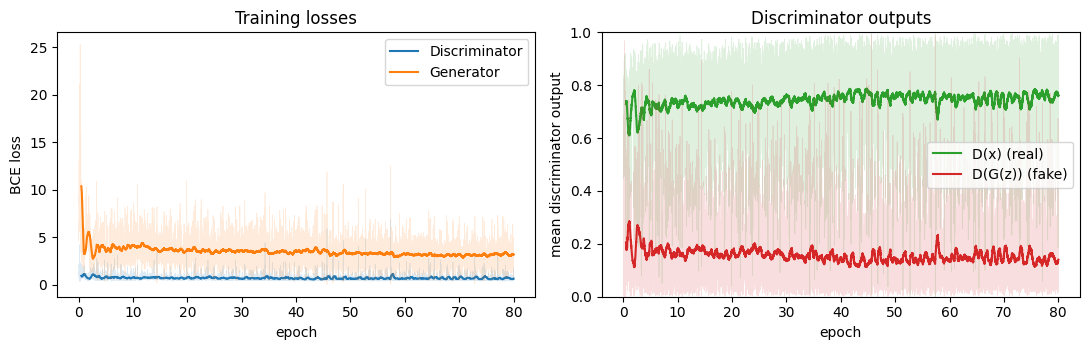

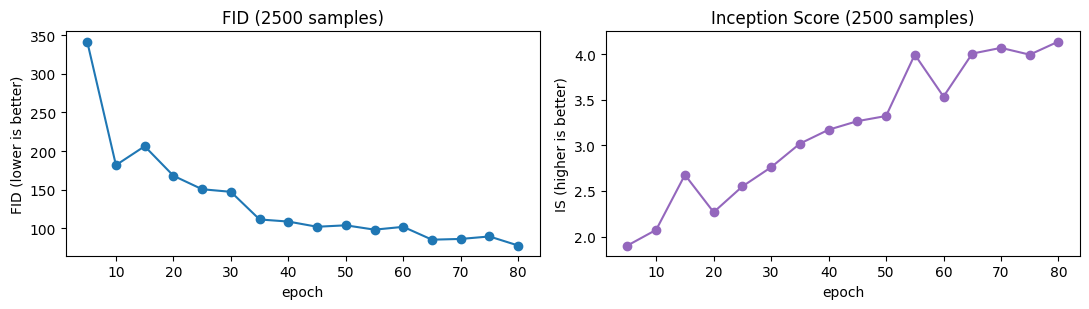

In [10]:
L = np.concatenate(iter_log)                      # (total_iters, 4)
x_ep = np.arange(1, len(L) + 1) / iters_per_epoch
def smooth(y, k=max(1, iters_per_epoch // 2)):
    return np.convolve(y, np.ones(k) / k, mode="valid")
xs = x_ep[len(x_ep) - len(smooth(L[:, 0])):]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for j, (lab, c) in enumerate([("Discriminator", "tab:blue"), ("Generator", "tab:orange")]):
    ax[0].plot(x_ep, L[:, j], color=c, alpha=0.15, lw=0.5)
    ax[0].plot(xs, smooth(L[:, j]), color=c, label=lab)
ax[0].set(xlabel="epoch", ylabel="BCE loss", title="Training losses"); ax[0].legend()
for j, (lab, c) in enumerate([("D(x) (real)", "tab:green"), ("D(G(z)) (fake)", "tab:red")], start=2):
    ax[1].plot(x_ep, L[:, j], color=c, alpha=0.15, lw=0.5)
    ax[1].plot(xs, smooth(L[:, j]), color=c, label=lab)
ax[1].set(xlabel="epoch", ylabel="mean discriminator output", title="Discriminator outputs", ylim=(0, 1)); ax[1].legend()
plt.tight_layout()
for ext in ("png", "pdf"): plt.savefig(os.path.join(OUT_DIR, f"loss_curves.{ext}"), bbox_inches="tight", dpi=200)
plt.show()

if eval_log:
    ep = [e["epoch"] for e in eval_log]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    ax[0].plot(ep, [e["fid"] for e in eval_log], "o-"); ax[0].set(xlabel="epoch", ylabel="FID (lower is better)", title=f"FID ({N_EVAL_TRACK} samples)")
    ax[1].plot(ep, [e["inception_score"] for e in eval_log], "o-", color="tab:purple"); ax[1].set(xlabel="epoch", ylabel="IS (higher is better)", title=f"Inception Score ({N_EVAL_TRACK} samples)")
    plt.tight_layout()
    for ext in ("png", "pdf"): plt.savefig(os.path.join(OUT_DIR, f"fid_is_curves.{ext}"), bbox_inches="tight", dpi=200)
    plt.show()

## 6. Final evaluation (more samples), best vs. last checkpoint

In [11]:
if best["state"] is None:   # e.g. FID was NaN at every eval
    best.update(epoch=last_epoch, state={k: v.cpu() for k, v in G.state_dict().items()})
G_best = Generator().to(device); G_best.load_state_dict(best["state"])
torch.manual_seed(SEED)
fid_last, is_last = evaluate(G, N_EVAL_FINAL)
fid_best, is_best = evaluate(G_best, N_EVAL_FINAL)
is_real = inception_score_real(N_EVAL_FINAL)
fid_real = fid_real_vs_real(N_EVAL_FINAL)
final = {
    f"last (epoch {last_epoch})": dict(FID=fid_last, IS=is_last),
    f"best (epoch {best['epoch']})": dict(FID=fid_best, IS=is_best),
    "real images": dict(FID=fid_real, IS=is_real),
}
print(f"Final metrics with {min(N_EVAL_FINAL, N)} samples (real-images FID = two disjoint halves of {min(N_EVAL_FINAL, N // 2)}):")
for k, v in final.items(): print(f"  {k:22s} FID {v['FID']:7.2f}   IS {v['IS']:.3f}")

Final metrics with 10000 samples (real-images FID = two disjoint halves of 10000):
  last (epoch 80)        FID   61.63   IS 4.112
  best (epoch 80)        FID   61.40   IS 4.206
  real images            FID    5.82   IS 7.584


## 7. Generated samples, training progress, latent interpolation, nearest neighbours

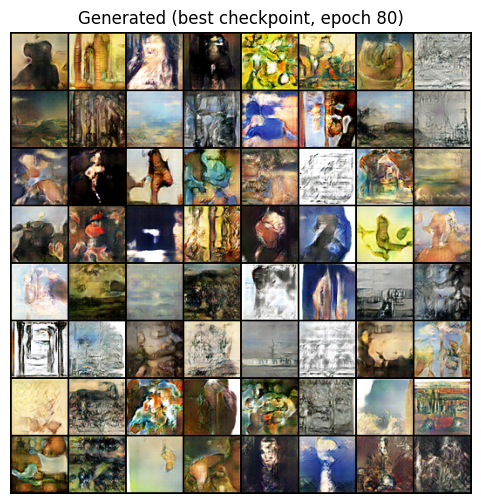

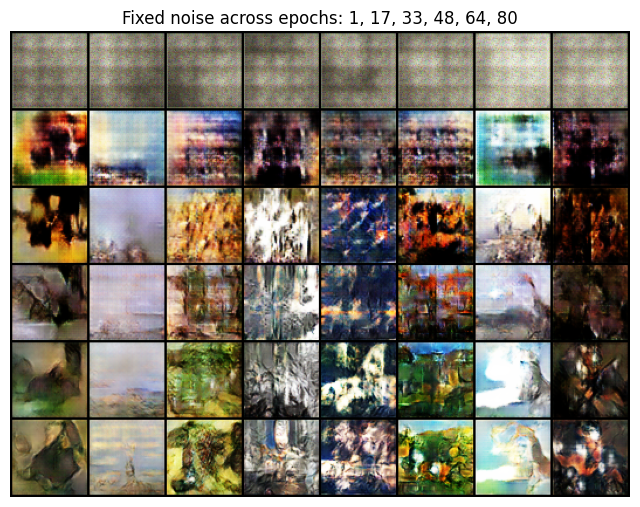

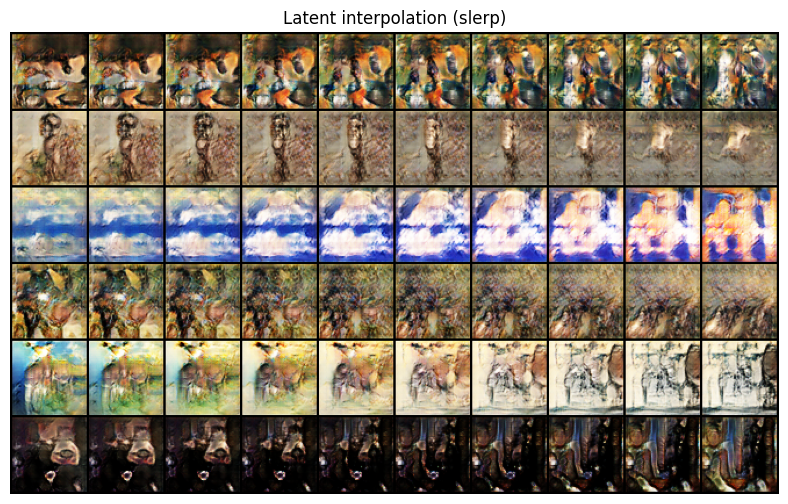

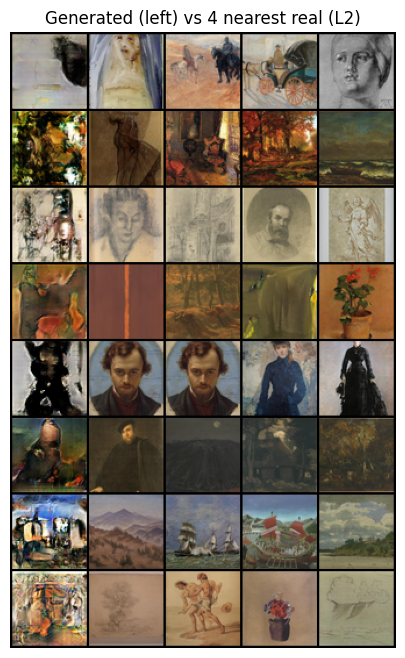

In [12]:
with torch.no_grad():
    G_best.eval()
    save_grid(G_best(torch.randn(64, NZ, 1, 1, device=device)), "generated_samples",
              title=f"Generated (best checkpoint, epoch {best['epoch']})")

    # Progress: same 8 latent codes at several epochs (one row per epoch)
    eps = sorted(set(int(round(x)) for x in np.linspace(1, last_epoch, 6)))
    prog = torch.cat([snapshots[e][:8] for e in eps])
    save_grid(prog, "progress", nrow=8, figsize=(8, 1.1 * len(eps)), title="Fixed noise across epochs: " + ", ".join(map(str, eps)))

    # Spherical interpolation between random latent pairs
    def slerp(a, b, t):
        a_n, b_n = a / a.norm(), b / b.norm()
        omega = torch.acos((a_n * b_n).sum().clamp(-1, 1))
        return (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega)
    rows = []
    for _ in range(6):
        z0, z1 = torch.randn(NZ, device=device), torch.randn(NZ, device=device)
        rows.append(torch.stack([slerp(z0, z1, t) for t in torch.linspace(0, 1, 10, device=device)]))
    save_grid(G_best(torch.cat(rows).view(-1, NZ, 1, 1)), "interpolation", nrow=10, figsize=(10, 6), title="Latent interpolation (slerp)")

    # Memorization check: nearest real training images in pixel space
    gen = G_best(torch.randn(8, NZ, 1, 1, device=device))
    flat_real = u8_to_float(data).flatten(1)          # N x 12288 (~1 GB fp32 for N = 20k)
    d2 = torch.cdist(gen.flatten(1), flat_real)       # 8 x N
    nn_idx = d2.topk(4, largest=False).indices
    del flat_real
    nn_rows = torch.cat([torch.cat([gen[i:i+1], u8_to_float(data[nn_idx[i]])]) for i in range(8)])
    save_grid(nn_rows, "nearest_neighbors", nrow=5, figsize=(5, 8), title="Generated (left) vs 4 nearest real (L2)")

## 8. Save results (and LaTeX snippets for the report)

In [13]:
results = dict(
    config={k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()},
    dataset=dict(n_images=N, n_styles=len(styles), styles=styles),
    params=dict(G=n_params(G), D=n_params(D)),
    gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    train_minutes=train_minutes, epochs_trained=last_epoch, iters_per_epoch=iters_per_epoch,
    best_epoch=best["epoch"], tracking_eval=eval_log, epoch_log=epoch_log, final_eval=final,
    n_eval_final=min(N_EVAL_FINAL, N),
)
with open(os.path.join(OUT_DIR, "results.json"), "w") as f: json.dump(results, f, indent=2)

print(r"""%% ---- hyperparameter table ----
\begin{tabular}{ll}
\toprule
Training images & %d WikiArt paintings (%d styles), %d$\times$%d, random h-flip \\
Latent dim / $n_{gf}$ / $n_{df}$ & %d / %d / %d \\
Params (G / D) & %.2fM / %.2fM \\
Optimizer & Adam, lr$_G$=%.0e, lr$_D$=%.0e, $\beta$=(%.1f, %.3f) \\
Batch size / epochs / iterations & %d / %d / %d \\
Loss & non-saturating BCE, real label %.1f \\
GPU / training time & %s / %.1f min \\
\bottomrule
\end{tabular}""" % (N, len(styles), IMG_SIZE, IMG_SIZE, NZ, NGF, NDF, n_params(G)/1e6, n_params(D)/1e6,
                     LR_G, LR_D, BETAS[0], BETAS[1], BATCH_SIZE, last_epoch, last_epoch * iters_per_epoch,
                     REAL_LABEL, results["gpu"], train_minutes))
print(r"""% ---- results table ----
\begin{tabular}{lcc}
\toprule
Model & FID $\downarrow$ & IS $\uparrow$ \\
\midrule""")
for k, v in final.items():
    fid_s = f"{v['FID']:.2f}"
    print(f"{k} & {fid_s} & {v['IS']:.2f} \\\\")
print(r"""\bottomrule
\end{tabular}""")

shutil.make_archive("/kaggle/working/hw2_outputs" if os.path.isdir("/kaggle/working") else os.path.join(OUT_DIR, "..", "hw2_outputs"), "zip", OUT_DIR)
print("saved:", sorted(os.listdir(OUT_DIR)))

% ---- hyperparameter table ----
\begin{tabular}{ll}
\toprule
Training images & 20000 WikiArt paintings (27 styles), 64$\times$64, random h-flip \\
Latent dim / $n_{gf}$ / $n_{df}$ & 100 / 64 / 64 \\
Params (G / D) & 3.58M / 2.77M \\
Optimizer & Adam, lr$_G$=2e-04, lr$_D$=2e-04, $\beta$=(0.5, 0.999) \\
Batch size / epochs / iterations & 128 / 80 / 12480 \\
Loss & non-saturating BCE, real label 0.9 \\
GPU / training time & Tesla T4 / 41.9 min \\
\bottomrule
\end{tabular}
% ---- results table ----
\begin{tabular}{lcc}
\toprule
Model & FID $\downarrow$ & IS $\uparrow$ \\
\midrule
last (epoch 80) & 61.63 & 4.11 \\
best (epoch 80) & 61.40 & 4.21 \\
real images & 5.82 & 7.58 \\
\bottomrule
\end{tabular}
saved: ['G_best.pt', 'ckpt_last.pt', 'fid_is_curves.pdf', 'fid_is_curves.png', 'generated_samples.pdf', 'generated_samples.png', 'interpolation.pdf', 'interpolation.png', 'loss_curves.pdf', 'loss_curves.png', 'nearest_neighbors.pdf', 'nearest_neighbors.png', 'progress.pdf', 'progress.png', 'r